# The CM truth as the reference: what we understand
**Why the truth.**
- Cluster-to-cluster references have their own problems:
  - zero field has a different diffusion, and merged clusters in bright regions (Ben, 78242 South R2 at φ ≈ 0.3 and
    1.3 rad);
  - the two no-beam runs differ in North by a rigid 2.4 mrad (83319 is the odd one).
- The CM stripes are fixed. Against the pad plane the pattern can only be **rotated and translated** (rigid), not
  stretched in R.

**The truth table.** The stripe rows have the same radii on both sides (design pattern):
- R1: 27.24–39.69 cm, every 1.132 cm;
- R2: 42.17–56.46 cm, every 2.041 cm;
- R3: 59.46–74.82 cm, every 2.194 cm.

Only the φ pattern (which stripes exist or are lit) differs.

**Steps.**
1. **Own matching.** The matcher's truth association fails for South no-beam. Here: nearest stripe under the current model,
   window 12 → 6 → 3 mm, iterated; (ring, 0.2 rad) cells with a large local spread (merged clusters) are masked.
2. **Rigid alignment from zero field, RΔφ only.** With no B, axisymmetric fields (IFC, OFC) move clusters only radially,
   so RΔφ measures only the rotation and the translation (−dx sinφ + dy cosφ). dR is not used for the parameters (it
   saturates, section 4), only to find the matching stripe.
3. **Corrected truth**, with a closure check; 3b: robustness (sector edges, pad modules, subsets).
4. **Why dR from CM clusters is not a linear measurement** (stripe rows on pad-row boundaries).
5. **Radial measurement from two-row clusters** (no beam 75073, B on).
6. **Magnetic-field alignment** (no beam 75073 vs the aligned truth): TPC tilt and TPC offset from the field axis.
7. **B_φ and B_r** on the aligned baseline: φ and R together.
8. **Step 4: IFC, OFC and CM z** on the aligned baseline; the field cage from zero field (two-row R).
9. Side: do PHGarfield's module frames explain the sector-edge swing?
10. **Beam:** keff on the aligned static model (same keff per GEM current on both sides), then closure: beam vs
    truth, vs no beam, vs field off; sagitta.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, bsnb as b, truthalign as ta, slidestyle
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 15, 'axes.titlesize': 16, 'axes.labelsize': 17, 'legend.fontsize': 13,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14, 'figure.titlesize': 17})
b.plt.rcParams.update(plt.rcParams)
def show(*figs):
    for f in figs:
        display(slidestyle.restyle(f))
    plt.close('all')

## 1. Own matching on zero field; masked cells
**What is plotted.** The residual per cluster after the alignment (RΔφ, then dR) in (φ, R). × = a masked (ring, 0.2 rad)
cell: local spread of dR above 2.5 mm or of RΔφ above 1.5 mm.

CONFIG  zero field 78242, IFC -60 V vs automatic, OFC 0, frames 0, survey x/y, z 0, tilt 0.16/0.85; own truth matching


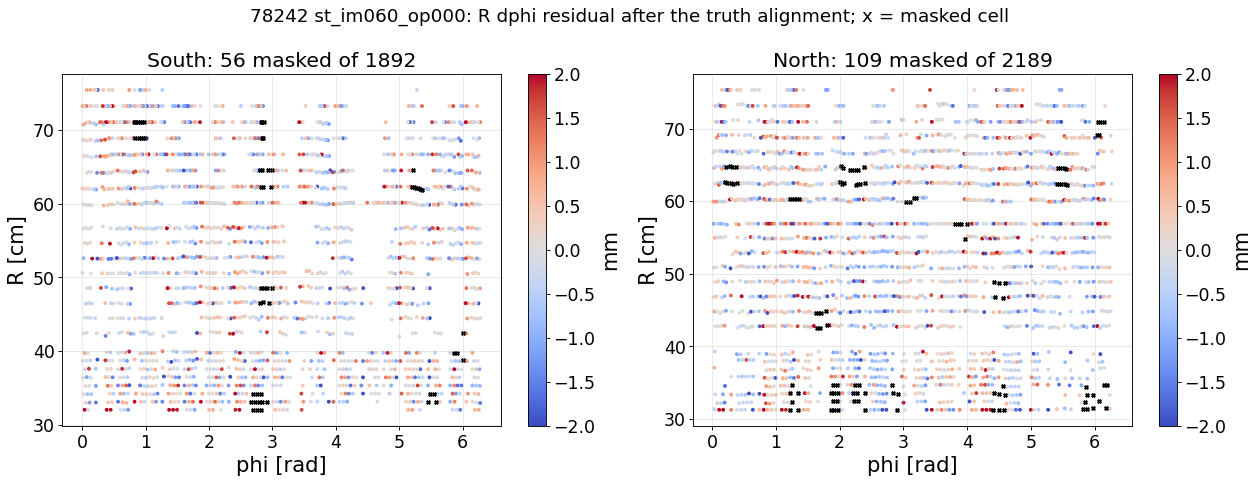

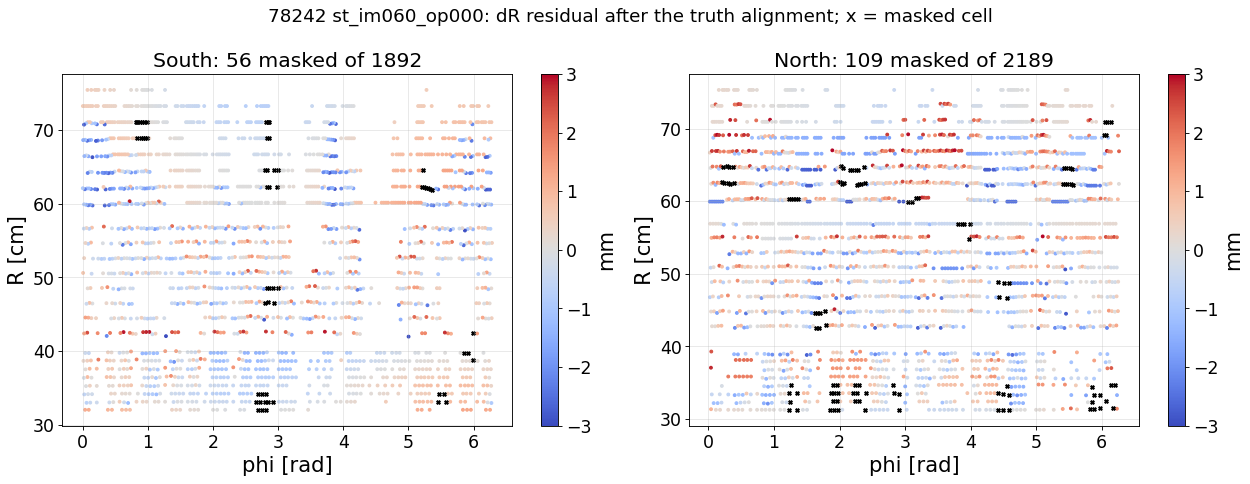

In [2]:
print('CONFIG  zero field 78242, IFC -60 V vs automatic, OFC 0, frames 0, survey x/y, z 0, tilt 0.16/0.85; own truth matching')
show(ta.fig_map('78242', 'st_im060_op000', 'res_p'), ta.fig_map('78242', 'st_im060_op000', 'res_r', vlim=3))

## 2. Rigid alignment of the truth from zero field
**What is plotted.** Rotation (left axis) and translation (right axis) of the CM pattern against the pads, for every
zero-field correction setting. The open markers on the right are the translation from no beam (B on; RΔφ ring profile
free, so the rotation is not measured there).

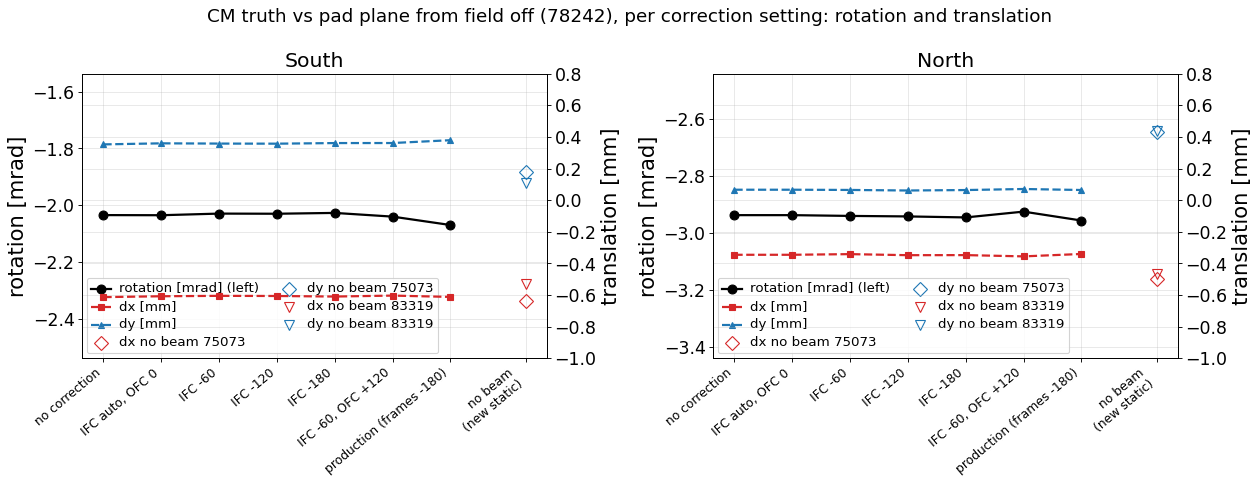

78242 noGarfield       S: rot -2.034 mrad  dx -0.613  dy +0.353 mm  | matched 1886/2824 used 1819  | resid MAD RDphi 0.703 dR 0.830 mm
78242 st_ip000_op000   S: rot -2.035 mrad  dx -0.607  dy +0.360 mm  | matched 1894/2824 used 1825  | resid MAD RDphi 0.697 dR 0.851 mm
78242 st_im060_op000   S: rot -2.029 mrad  dx -0.605  dy +0.358 mm  | matched 1892/2824 used 1836  | resid MAD RDphi 0.702 dR 0.827 mm
78242 st_im120_op000   S: rot -2.029 mrad  dx -0.606  dy +0.357 mm  | matched 1888/2824 used 1832  | resid MAD RDphi 0.703 dR 0.834 mm
78242 st_im180_op000   S: rot -2.026 mrad  dx -0.609  dy +0.361 mm  | matched 1885/2824 used 1826  | resid MAD RDphi 0.705 dR 0.830 mm
78242 st_im060_op120   S: rot -2.039 mrad  dx -0.603  dy +0.361 mm  | matched 1896/2824 used 1827  | resid MAD RDphi 0.705 dR 0.836 mm
78242 st_auto_f180     S: rot -2.069 mrad  dx -0.611  dy +0.379 mm  | matched 1926/2824 used 1877  | resid MAD RDphi 0.605 dR 0.866 mm
78242 noGarfield       N: rot -2.937 mrad  dx -0.345  d

In [3]:
show(ta.fig_params())
for s in (0, 1):
    for t, l in ta.OFF_TAGS:
        print(ta.summary(ta.A('78242', t, s)))

**Result.**

| | rotation | dx | dy |
|---|---|---|---|
| South | −2.03 mrad | −0.61 mm | +0.36 mm |
| North | −2.94 mrad | −0.34 mm | +0.07 mm |

Identical within 0.04 mrad / 0.03 mm for every IFC / OFC / frame setting. (Using the saturated dR as well pulled the
South translation by 0.1 mm: −0.53, +0.25.)

## 3. Corrected truth and closure
The stripe table is rotated and shifted by the result of section 2, and the alignment is redone. Everything should be 0.

CONFIG  truth corrected with {'South': [-2.029, -0.605, 0.358], 'North': [-2.939, -0.341, 0.065]} (rot mrad, dx mm, dy mm)


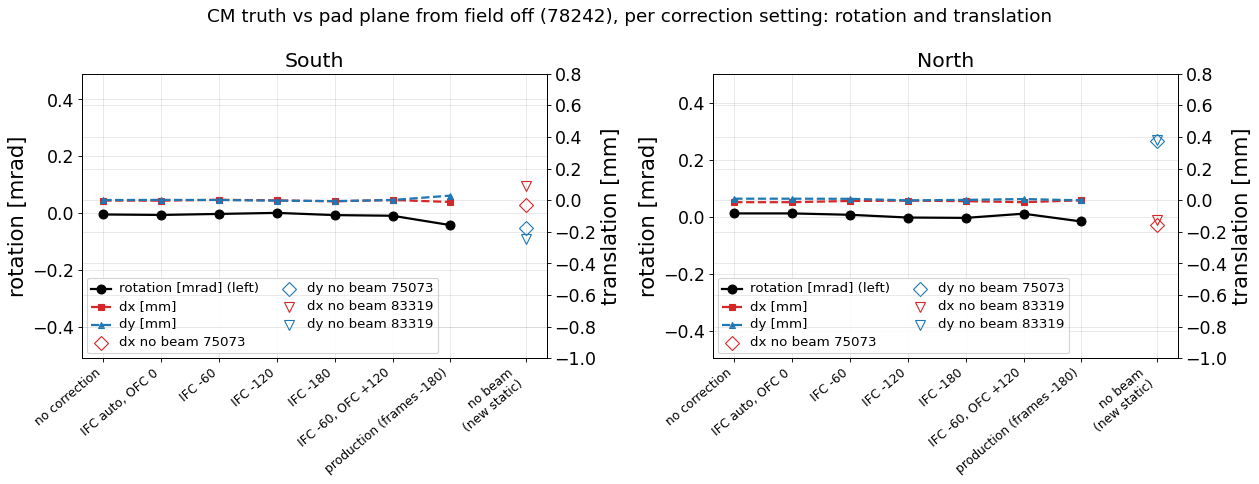

In [4]:
pcorr = ta.correct_truth()
print('CONFIG  truth corrected with', {c.SIDES[s]: [round(v, 3) for v in pcorr[s]] for s in pcorr}, '(rot mrad, dx mm, dy mm)')
show(ta.fig_params())

## 3b. Is the CM alignment robust? Sector edges, pad modules, subsets
**Checks.** If rotation + translation describe the CM pattern against the pads, any subset of clusters (two-row /
one-row, one module ring, half or quarter of φ) must give the same values.

**What is plotted.**
- RΔφ vs φ mod 30°: the pad-sector edges.
- The rigid fit from subsets (sector edges excluded): red band = all clusters.
- Median RΔφ per pad module after the rigid fit: zero field and no beam.
- The joint fit (rigid + 36 pad-module offsets; per module ring the offsets have zero mean and no first harmonic, so
  they cannot take the rotation or the translation) from the same subsets.

CONFIG  zero field 78242, IFC automatic, OFC 0, frames 0, z 0 (bsR, with per-row charge); no beam 75073 step-2 baseline (bsQ q_base)


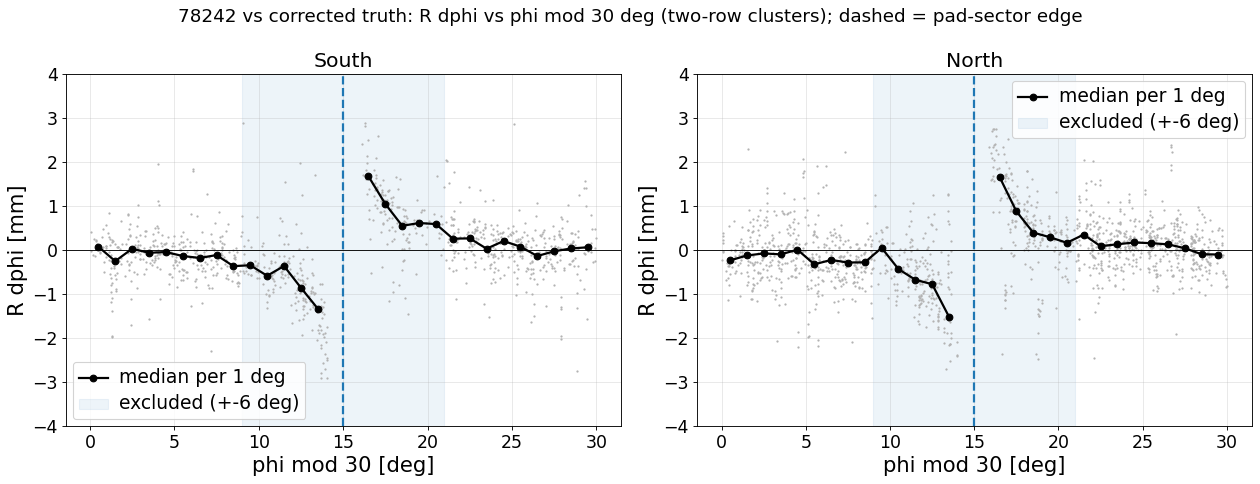

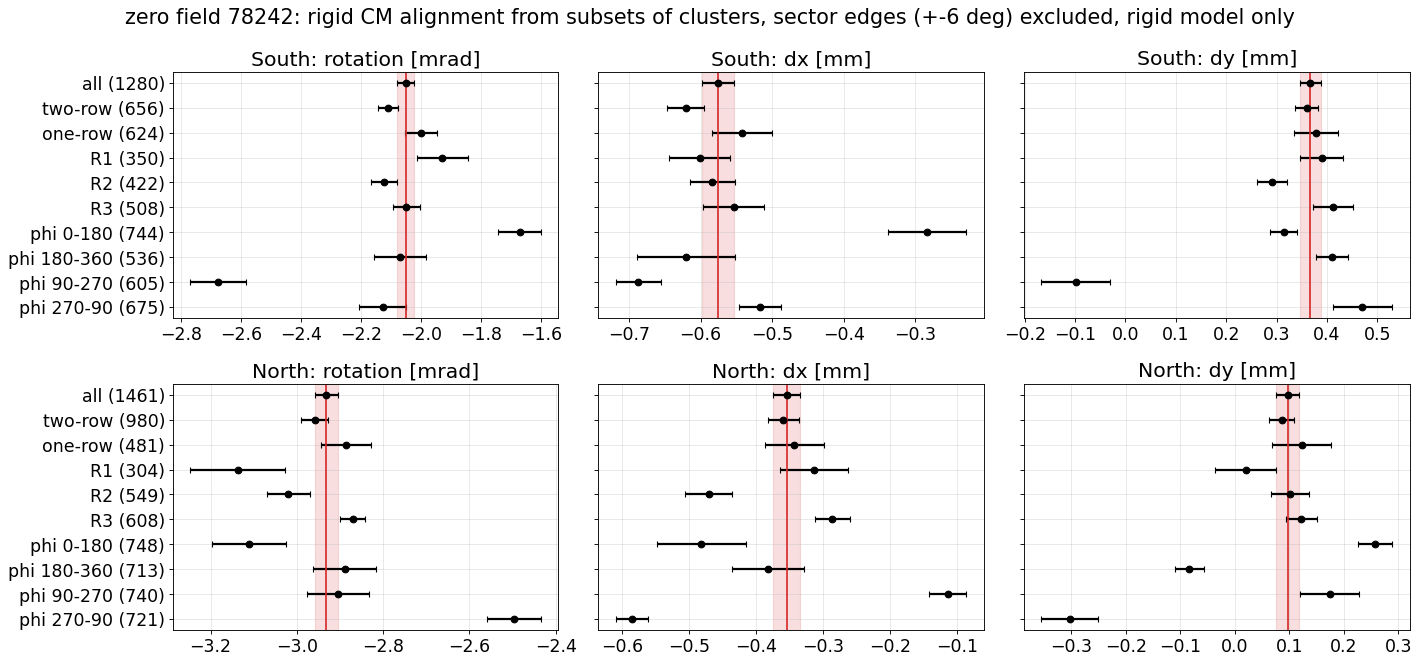

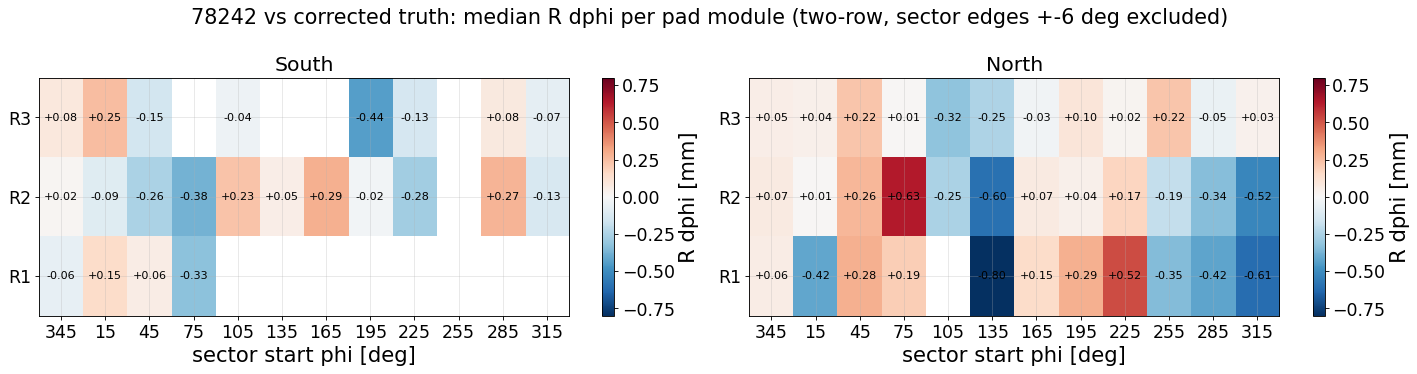

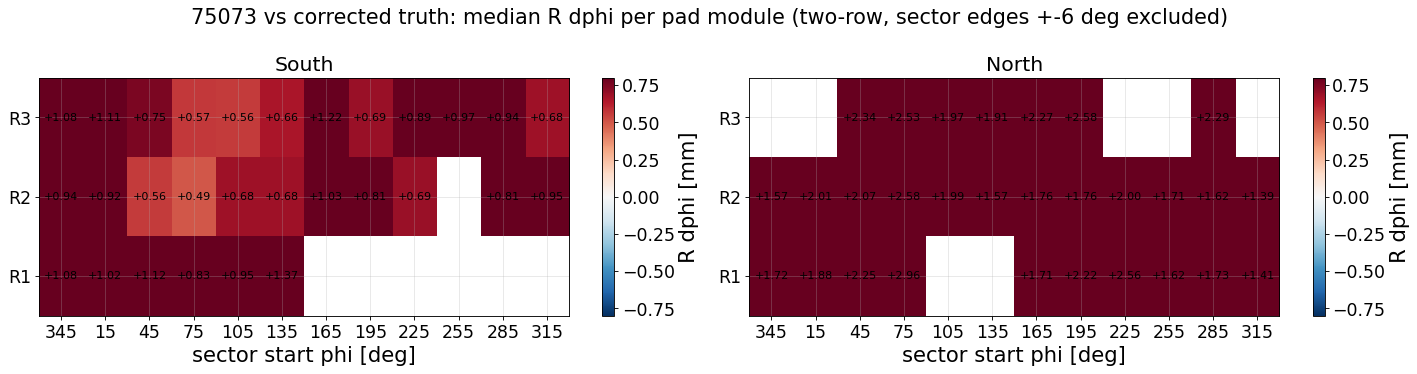

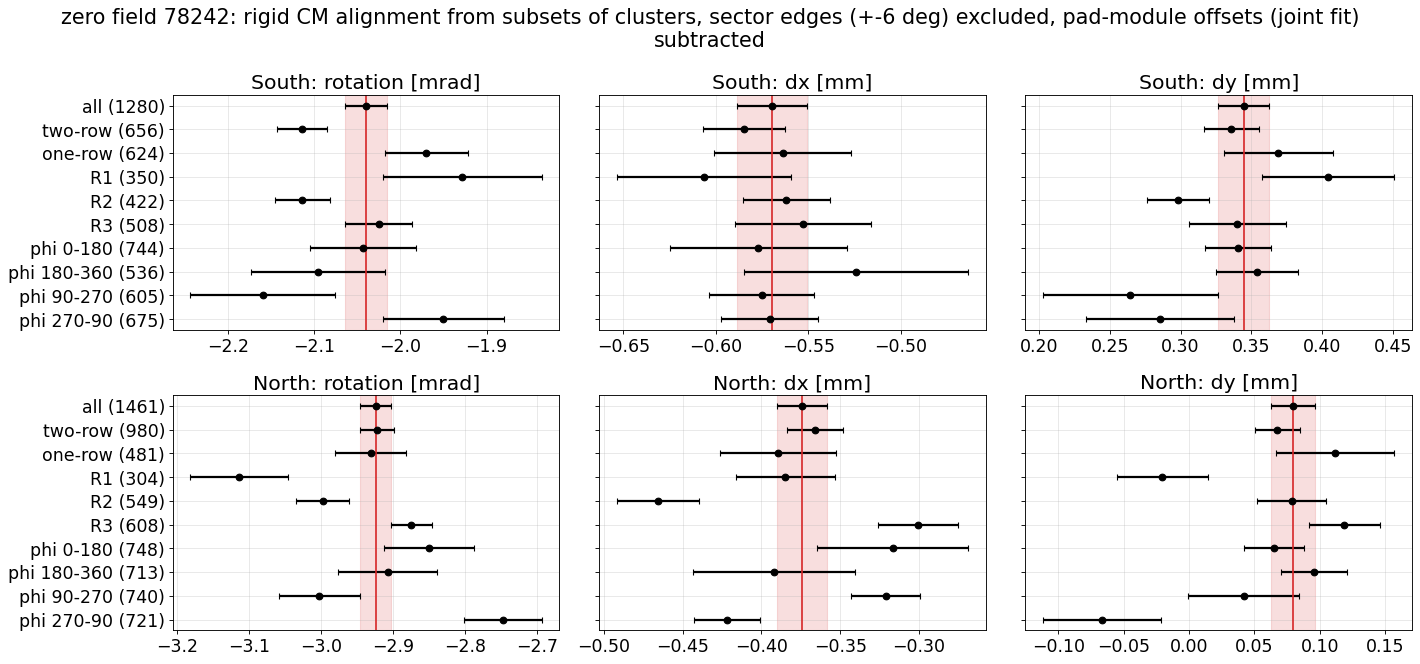

South joint fit, all: rot -2.040 +- 0.024 mrad, dx -0.570 +- 0.019, dy +0.345 +- 0.018 mm
North joint fit, all: rot -2.924 +- 0.021 mrad, dx -0.374 +- 0.016, dy +0.079 +- 0.017 mm


In [5]:
print('CONFIG  zero field 78242, IFC automatic, OFC 0, frames 0, z 0 (bsR, with per-row charge); no beam 75073 step-2 baseline (bsQ q_base)')
show(ta.fig_edge_profile(), ta.fig_align_subsets(), ta.fig_module_map(), ta.fig_module_map('75073', 'q_base', 'raw_bsQ0'),
     ta.fig_align_subsets(joint=True))
for s in (0, 1):
    for nm, sol, e, n in ta.align_subsets(s, joint=True)[:1]:
        print(f"{c.SIDES[s]} joint fit, all: rot {sol[0]:+.3f} +- {e[0]:.3f} mrad, dx {sol[1]:+.3f} +- {e[1]:.3f}, dy {sol[2]:+.3f} +- {e[2]:.3f} mm")

**Result.**
- **Sector edges:** within ±4° of a pad-sector edge RΔφ swings by ±2.5 mm, even at zero field (electrons pushed away from
  the gap between the modules). Excluded (±6°) from all fits.
- **Rigid model only:** the full circle is stable, but the φ halves / quarters disagree by up to 0.6 mrad and 0.3 mm
  (5–7σ). The rigid model is not complete.
- **Pad-module offsets:** 0.2–0.8 mm, coherent over R1/R2/R3 in a sector. **The same pattern with and without
  magnetic field** (correlation 0.60 South, 0.75 North; rms of the difference 0.17 / 0.24 mm): geometry (or a field
  that does not depend on B), so it belongs to the alignment.
- **Rigid + module offsets:** the φ subsets agree (pulls mostly < 1.5σ) and the values do not move:
  South −2.04 mrad, (−0.57, +0.35) mm; North −2.92 mrad, (−0.37, +0.08) mm (rigid only: −2.05, (−0.58, +0.37);
  −2.93, (−0.36, +0.10)). Left: the rotation differs between module rings by up to 0.24 mrad (North R1 −3.11 vs R3
  −2.87): the module rings are not rotated together. Systematic of the CM rotation ≈ ±0.1 mrad.

## 4. Why dR from CM clusters is not a linear measurement
**The geometry.** In the local pad frame (the frame of the CM-cluster R; the pad map is stored with the survey shift
(−1.68, −0.34) mm, removed here), the CM stripe rows lie on pad-row boundaries: boundary − stripe radius ≤ 0.06 mm in
R2 / R3 and 0.07–0.15 mm in R1. A CM cluster's R is the ADC-weighted average of the pad-row centres it collects charge on. So the measured R of
a stripe can only be between "all charge on the inner row" (−½ pitch) and "all charge on the outer row" (+½ pitch).

The pitch is 0.57 / ≈ 1.03 / ≈ 1.1 cm in R1 / R2 / R3. As soon as the charge cloud is shifted by more than its own width
(diffusion + stripe width), the measured R saturates at ±½ pitch, whatever the true shift is.

**What is plotted.**
- The fraction of each stripe row's charge on the outer pad row: zero field vs no beam (B on).
- The reconstructed cluster R in a window of R3, with the truth rows.

CONFIG  pad-level ADC maps (hADC_perLaserFlash, laser-cluster QA) and matcher QA, no correction


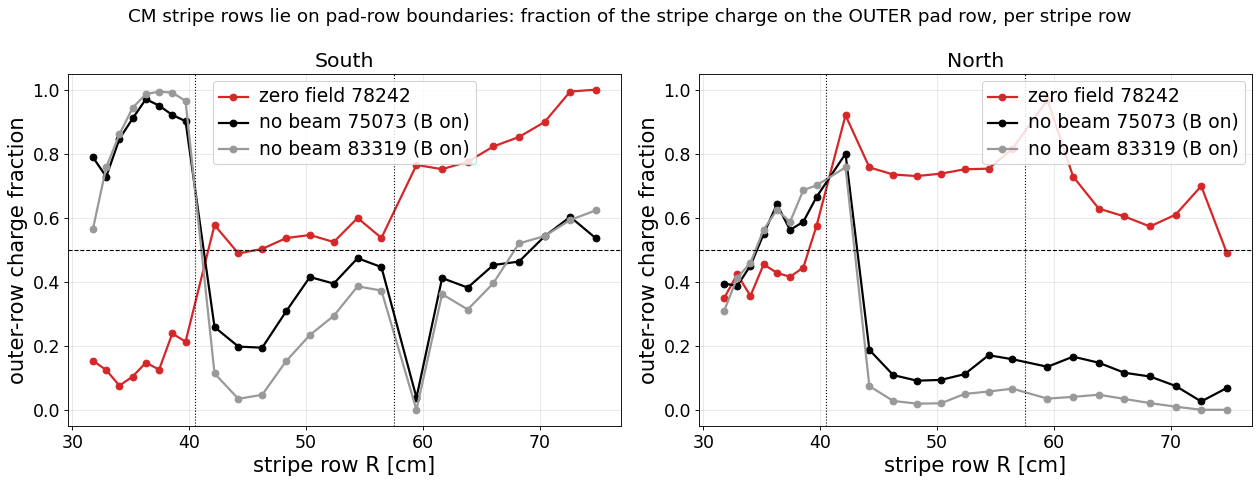

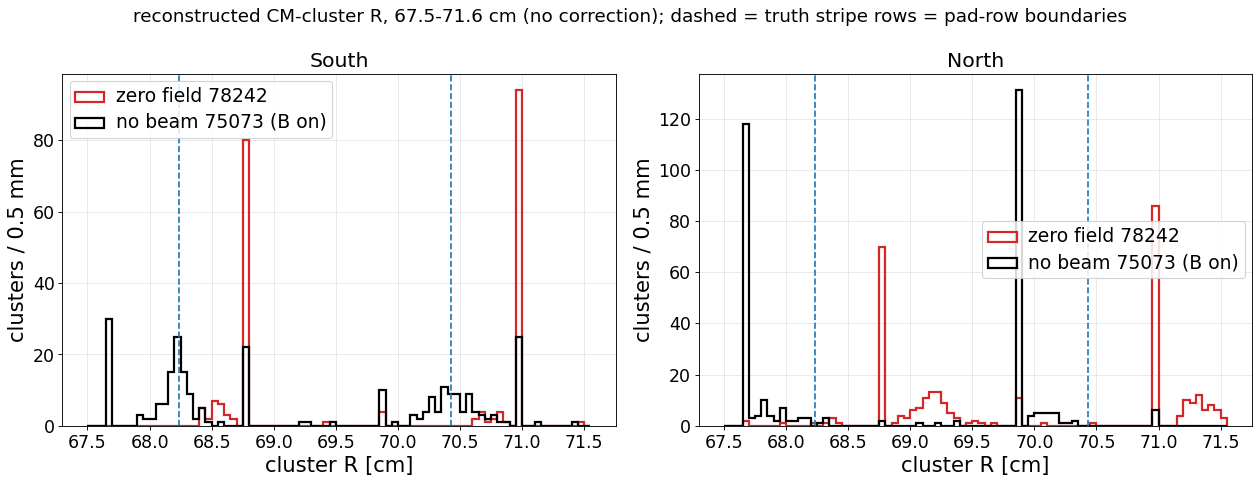

zero field 78242       S: boundary - stripe max |0.15| mm; outer-row fraction R1 0.08-0.24, R2 0.49-0.60, R3 0.75-1.00
zero field 78242       N: boundary - stripe max |0.15| mm; outer-row fraction R1 0.35-0.57, R2 0.73-0.92, R3 0.49-0.97
no beam 75073 (B on)   S: boundary - stripe max |0.15| mm; outer-row fraction R1 0.73-0.97, R2 0.19-0.47, R3 0.04-0.60
no beam 75073 (B on)   N: boundary - stripe max |0.15| mm; outer-row fraction R1 0.39-0.66, R2 0.09-0.80, R3 0.03-0.17
no beam 83319 (B on)   S: boundary - stripe max |0.15| mm; outer-row fraction R1 0.57-0.99, R2 0.03-0.39, R3 0.00-0.62
no beam 83319 (B on)   N: boundary - stripe max |0.15| mm; outer-row fraction R1 0.31-0.70, R2 0.02-0.76, R3 0.00-0.05


In [6]:
print('CONFIG  pad-level ADC maps (hADC_perLaserFlash, laser-cluster QA) and matcher QA, no correction')
show(ta.fig_row_split(), ta.fig_r_quant())
for run, lab, _ in ta.SPLIT_RUNS:
    for s in (0, 1):
        off, f = ta.row_split(run, s)
        print(f"{lab:22s} {c.SIDES[s][0]}: boundary - stripe max |{np.max(np.abs(off)):.2f}| mm; outer-row fraction R1 {np.nanmin(f[:8]):.2f}-{np.nanmax(f[:8]):.2f}, "
              f"R2 {np.nanmin(f[8:16]):.2f}-{np.nanmax(f[8:16]):.2f}, R3 {np.nanmin(f[16:]):.2f}-{np.nanmax(f[16:]):.2f}")

**Result.**
- **Zero field, South R3:** 75–100 % of the charge on the outer pad row (100 % at the outermost rows): the cluster R
  approaches the outer row centre, +½ pitch ≈ +5.5 mm.
- **B on snaps too:**
  - North 75073 R2 / R3: 3–19 % on the outer row (the first R2 row: 80 %), so the clusters sit on the inner row centres (single 0.5 mm bins with
    > 100 clusters in the histogram; the one-row clusters sit on the row centre to 10⁻³ mm);
  - South 75073 is more evenly split.
- So the measured dR of CM clusters saturates at ±½ pitch, in zero field and with B on alike. The flat zero-field dR
  (+3.5 South, +7 North mm, steps at the module boundaries) is mostly this saturation, not a measured radial distortion.
  **dR of CM clusters cannot be fitted linearly** (no field-cage fit from it).
- The split itself still carries the information: δ = σ Φ⁻¹(f), with σ the cloud width (diffusion + stripe width). Not
  done yet.
- **RΔφ is unaffected** by the radial quantisation, so the rigid truth alignment from zero field (sections 2–3) stands.

## 5. Radial measurement from two-row clusters (no beam 75073, B on)
**Per cluster** (raw R, local frame; the stripe from the matching of the corrected tag, same cluster list):
- **one-row**: R on a pad-row centre (to 0.02 mm), saturated, no radial information beyond the side;
- **two-row**: R between the centres of two adjacent rows, outer-row fraction f = (R − c_in) / pitch, boundary b between them.

| 75073, good cells | one-row | two-row | other (module gap) |
|---|---|---|---|
| South | 280 | 1365 | 51 |
| North | 653 | 1426 | 31 |

**Forward model.** The correction model predicts where the stripe charge lands:
landing = corrected truth − (correction applied to the cluster). For a Gaussian cloud of width σ centred at the landing,
Φ⁻¹(f) = (landing − b + miss) / σ, where miss = the radial distortion the model does not describe.

**What is plotted.**
- Φ⁻¹(f) vs the predicted landing − b for two-row clusters (new static model). The line fit gives an effective σ and the
  miss per module. The effective σ (1.3–1.6 mm R1, 2.5–2.9 mm R2 / R3) also absorbs the model's scatter, so it is an upper
  limit, not the cloud width.
- **σ-free:** clusters with a balanced split (0.3 < f < 0.7) landed within ±0.5 σ of the boundary, so their miss is
  −(predicted landing − b), with no σ. Solid = balanced clusters; dotted = all two-row clusters with the effective σ.

CONFIG  75073, production static (cdb_st) and new static (st_ns: B_r 0.8, IFC S -60 / N -120, frames 0); corrected truth


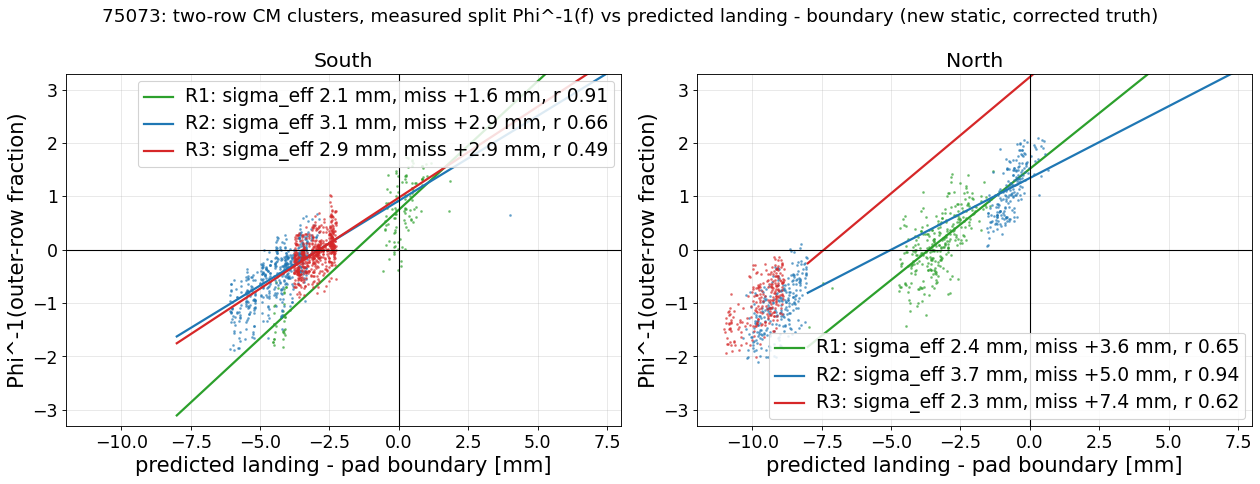

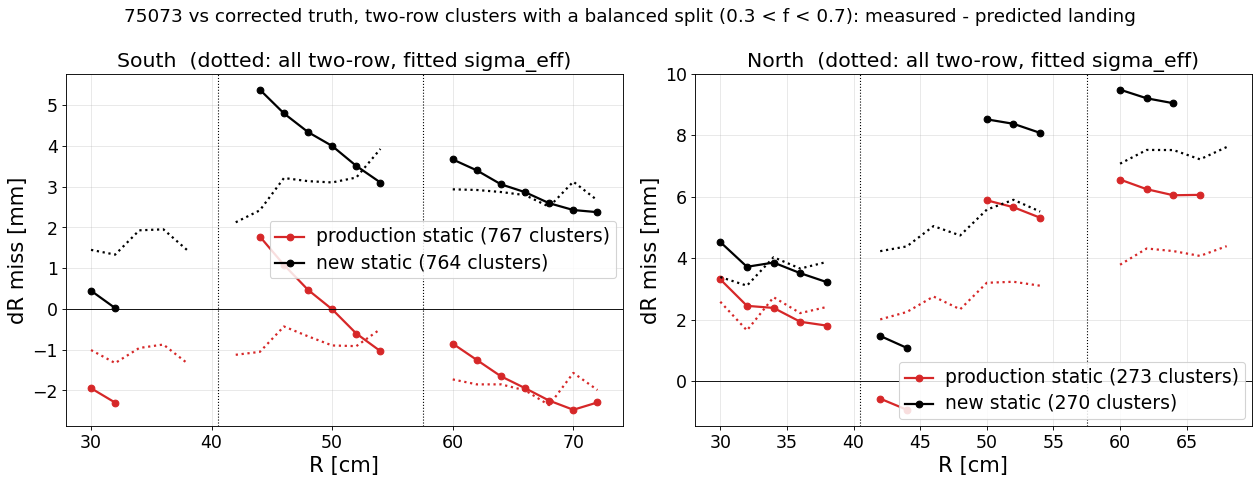

In [7]:
print('CONFIG  75073, production static (cdb_st) and new static (st_ns: B_r 0.8, IFC S -60 / N -120, frames 0); corrected truth')
show(ta.fig_split_model(), ta.fig_bal())

**Result.**
- The split follows the predicted landing (correlation 0.84–0.94 North, 0.95 South R1): the forward model is right, and
  the two-row clusters measure the radial landing.
- Neither static model lands the charge where the data put it:
  - production: South −1…−2 mm (R3), North +2…+6 mm;
  - new static: South +2.5…+5 mm, North +3…+9 mm.
- The miss has a shape in R inside the modules (South R2: −2.3 mm over 44–54 cm in both models). A field cage
  (E_r ∝ 1/r from the IFC) or a different radial distortion is needed; the B-on IFC × OFC grid (bsW, frames 0, B_r 1,
  tilt as CDB) gives the response.
- The two methods differ by up to 2 mm where the effective σ is large: the balanced clusters (σ-free) are the measurement.

## 6. Magnetic-field alignment: TPC tilt and offset from the field axis (no beam 75073)
Plan: (1) truth vs zero field → CM alignment (sections 2–3); **(2) aligned truth vs no beam → TPC vs magnetic field**;
(3) B_φ / B_r; (4) z shift, IFC / OFC if needed; (5) beam → space charge. RΔφ only.

**Why a sine.** A tilt of the TPC against the field, or an offset of the TPC from the field axis, gives the drift a
B_r that depends on φ, and E × B turns it into a first harmonic of RΔφ in φ:
- **tilt** → the sine flips sign between South and North (antisymmetric);
- **offset from the field axis** (off-axis B_r) → the same sine on both sides (symmetric).

The CM pattern itself (section 2) is aligned, so what is left is the TPC vs the field.

**What is plotted.**
- The first harmonic of RΔφ per module ring with the production tilt (0.16 / 0.85 mrad), split into the symmetric and
  antisymmetric parts.
- Linear model from the tilt grid (rot_x, rot_y) and the field-map shift scan: measured with the production tilt, best
  tilt only, best tilt + offset (predicted).
- Measured with dedicated runs (tilt 0.38 / 0.97, field map moved).

CONFIG  75073; RDphi vs phi per ring, sector edges excluded


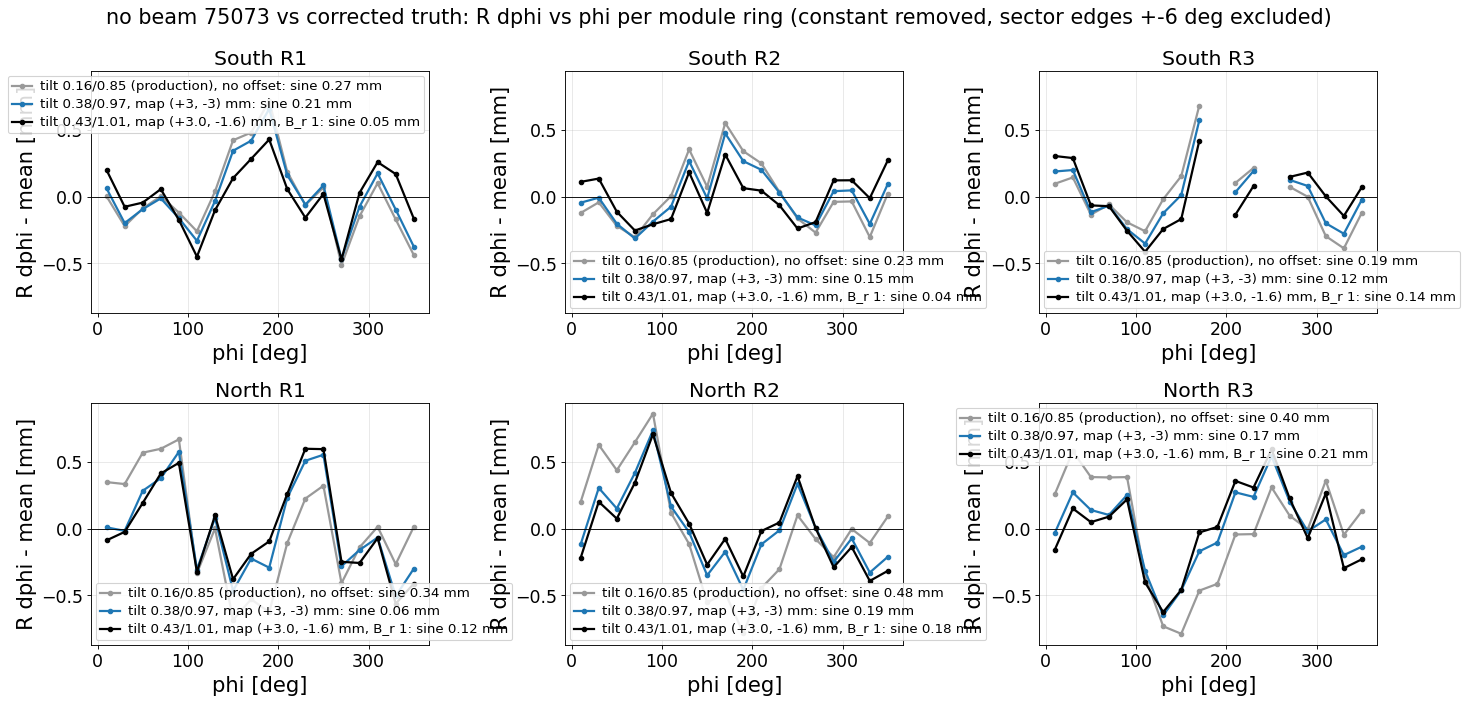

as before                                               best tilt 0.43 / 1.01 mrad, field map (+3.0, -1.6) mm
sector edges excluded                                   best tilt 0.46 / 1.03 mrad, field map (+2.4, -1.2) mm
edges excluded + zero-field module offsets subtracted   best tilt 0.46 / 1.00 mrad, field map (+2.6, -1.8) mm


In [8]:
print('CONFIG  75073; RDphi vs phi per ring, sector edges excluded')
show(ta.fig_step2_phi())
for ec, mc, lab in ((0, False, 'as before'), (6, False, 'sector edges excluded'), (6, True, 'edges excluded + zero-field module offsets subtracted')):
    F = ta.tilt_offset_fit_mc('75073', edge_cut=ec, mcorr=mc)
    print(f"{lab:55s} best tilt {F['best'][0]:.2f} / {F['best'][1]:.2f} mrad, field map ({F['best'][2]:+.1f}, {F['best'][3]:+.1f}) mm")

CONFIG  75073; tilt / map scans with the static model of st_ns (B_r 0.8, IFC S -60 / N -120, frames 0); last bar: B_r 1, IFC 0


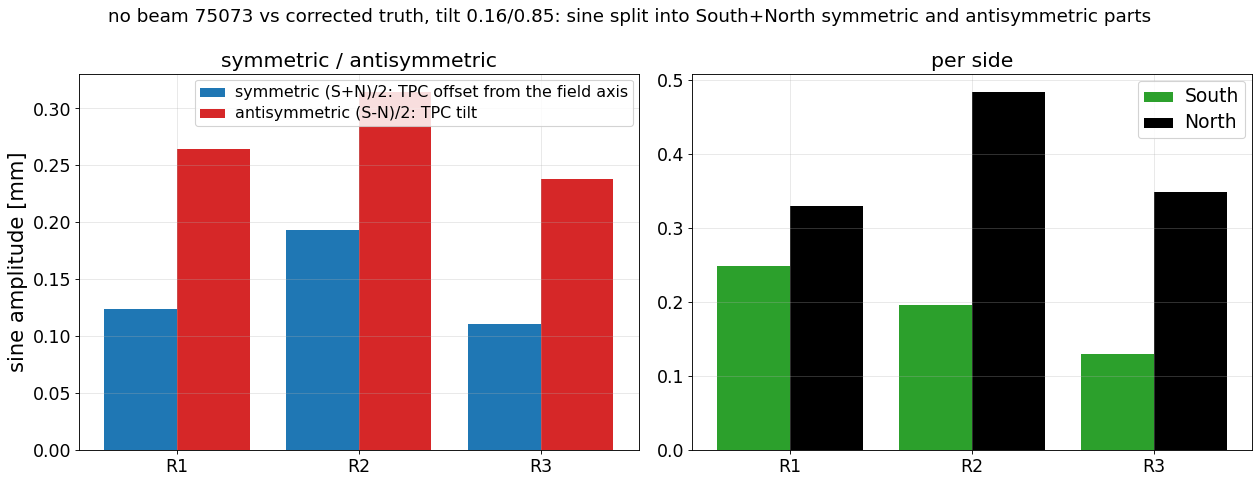

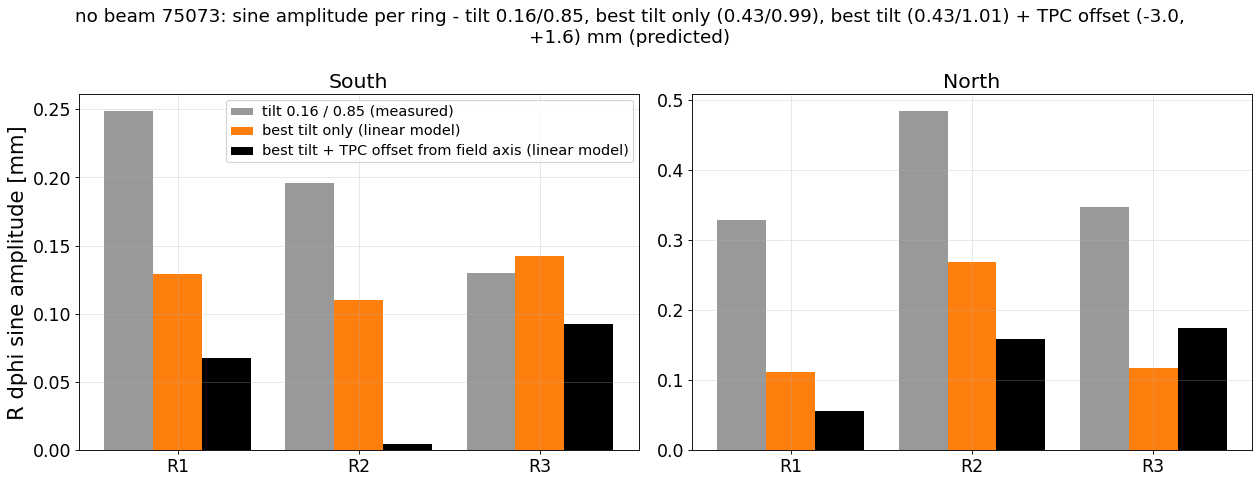

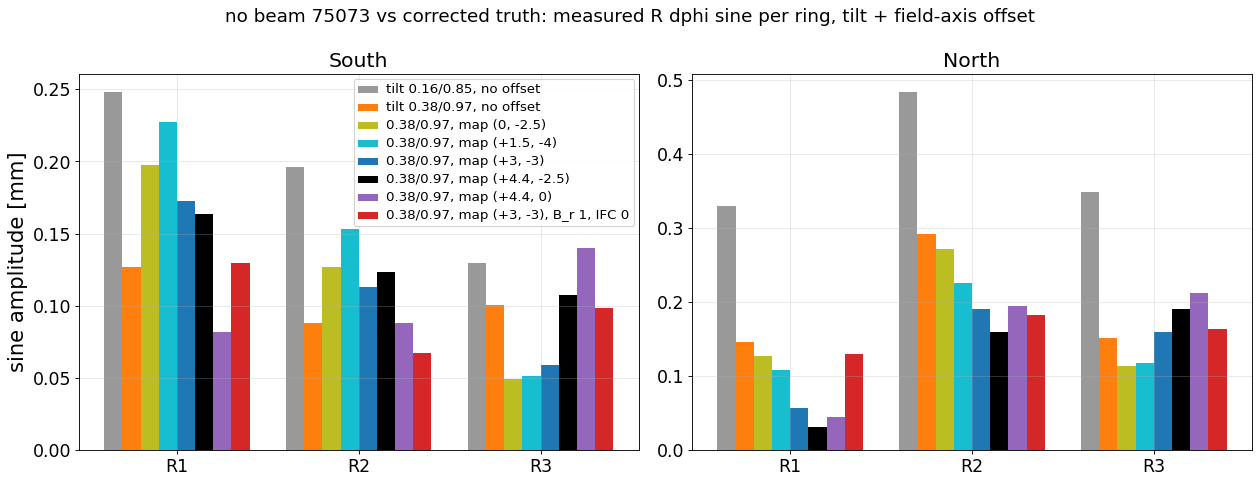

best: tilt rot_x 0.43, rot_y 1.01 mrad; field map moved (+3.0, -1.6) mm = TPC (-3.0, +1.6) mm from the field axis
tilt only: rot_x 0.43, rot_y 0.99 mrad
tilt 0.16/0.85, no offset                  RDphi sine rms 0.31 mm
tilt 0.38/0.97, no offset                  RDphi sine rms 0.17 mm
0.38/0.97, map (0, -2.5)                   RDphi sine rms 0.16 mm
0.38/0.97, map (+1.5, -4)                  RDphi sine rms 0.16 mm
0.38/0.97, map (+3, -3)                    RDphi sine rms 0.14 mm
0.38/0.97, map (+4.4, -2.5)                RDphi sine rms 0.14 mm
0.38/0.97, map (+4.4, 0)                   RDphi sine rms 0.14 mm
0.38/0.97, map (+3, -3), B_r 1, IFC 0      RDphi sine rms 0.13 mm


In [9]:
print('CONFIG  75073; tilt / map scans with the static model of st_ns (B_r 0.8, IFC S -60 / N -120, frames 0); last bar: B_r 1, IFC 0')
show(ta.fig_sym_anti('75073'), ta.fig_tilt_offset('75073'), ta.fig_confirm('75073'))
T = ta.tilt_offset_fit('75073')
print('best: tilt rot_x %.2f, rot_y %.2f mrad; field map moved (%+.1f, %+.1f) mm = TPC (%+.1f, %+.1f) mm from the field axis' % (T['best'][0], T['best'][1], T['best'][2], T['best'][3], -T['best'][2], -T['best'][3]))
print('tilt only: rot_x %.2f, rot_y %.2f mrad' % T['tilt_only'])
for tag, lab, _ in ta.CONFIRM:
    S = ta.sines('75073', tag)
    print(f"{lab:42s} RDphi sine rms {np.sqrt(np.mean(np.sum(S ** 2, -1))):.2f} mm")

**Result.**
- With the production tilt the sine is 0.13–0.48 mm, half antisymmetric (tilt) and half symmetric (offset from the field
  axis).
- Best: **tilt rot_x 0.43, rot_y 1.01 mrad**, field map moved **(+3.0, −1.6) mm** (the TPC (−3.0, +1.6) mm from the field
  axis). Measured with tilt 0.38 / 0.97 and map (+3, −3): RΔφ sine rms 0.31 → 0.13–0.14 mm.
- The field-map y position is weakly constrained (the same sine within 0.03 mm for −1.6 … −3 mm). The tilt is not.
- **Robust:** with the sector edges excluded and the zero-field pad-module offsets subtracted the fit gives tilt
  0.46 / 1.00 mrad and map (+2.6, −1.8) mm (as before: 0.43 / 1.01, (+3.0, −1.6)); the sine at the baseline is then
  0.10 mm. Tilt ±0.03 mrad, map ±0.5 mm.
- The structure left after the sine (RΔφ vs φ, ±0.5 mm) is the pad-module pattern of section 3b, already there at
  zero field.
- Independent of the static model: B_r 0.8 / IFC −60, −120 and B_r 1 / IFC 0 give the same sine.
- Not a CM effect: the CM alignment comes from zero field, where the tilt and the field position do not enter (local pad
  frame), so it does not need to be redone.

## 7. Step 3: B_φ and B_r (no beam 75073, step-2 baseline)
Baseline: tilt 0.43 / 1.01 mrad, field map (+3.0, −1.6) mm, B_r 1, frames 0, IFC / OFC 0. What is left is a RΔφ offset
of the **same sign in both halves**: South +0.7…+1.2 mm, North +1.6…+2.4 mm.

**Responses (PHGarfield, linear):**
- added B_φ = B_z·a: RΔφ ±0.89 mm per mrad, opposite in the two halves, flat in R; R only ∓0.35 mm per mrad (ωτ ≈ 2.5);
- B_r scale: RΔφ −0.4…−0.8 mm per −0.1, and **R ≈ +1.8 mm per −0.1** (electrons follow the field lines: B_r moves
  the charge mostly radially, via B_r·B_z, and less in φ).

**What is plotted.**
- RΔφ vs R for the baseline, B_φ per side, a common B_φ, and B_r × 0.8 / 0.9 / 1.1.
- Mean RΔφ (φ) and mean radial miss of the balanced two-row clusters (R) vs the B_r scale.

CONFIG  75073, step-2 baseline; bsQ scan (B_phi / B_r); truth aligned from RDphi only


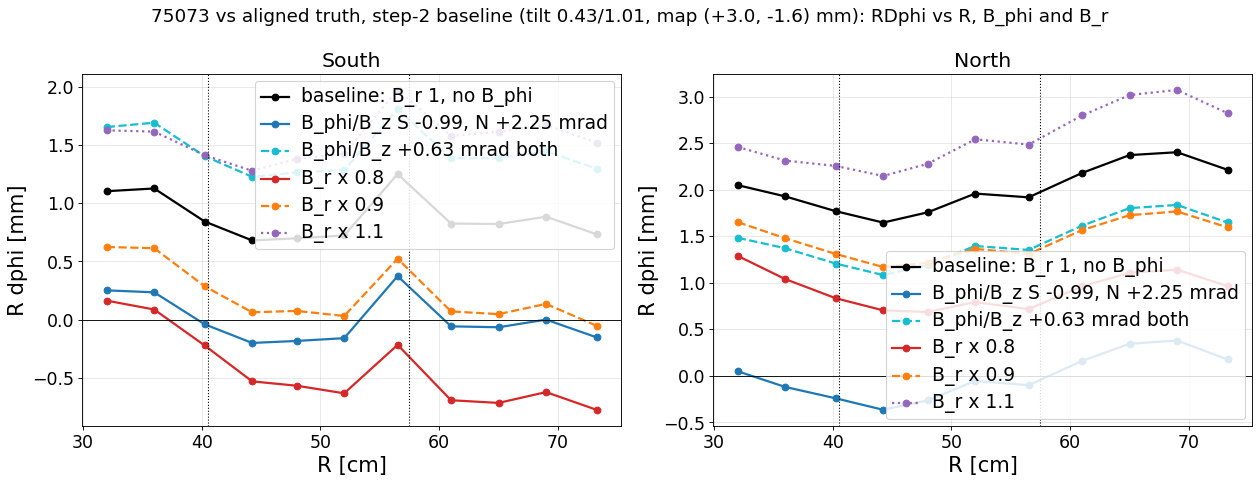

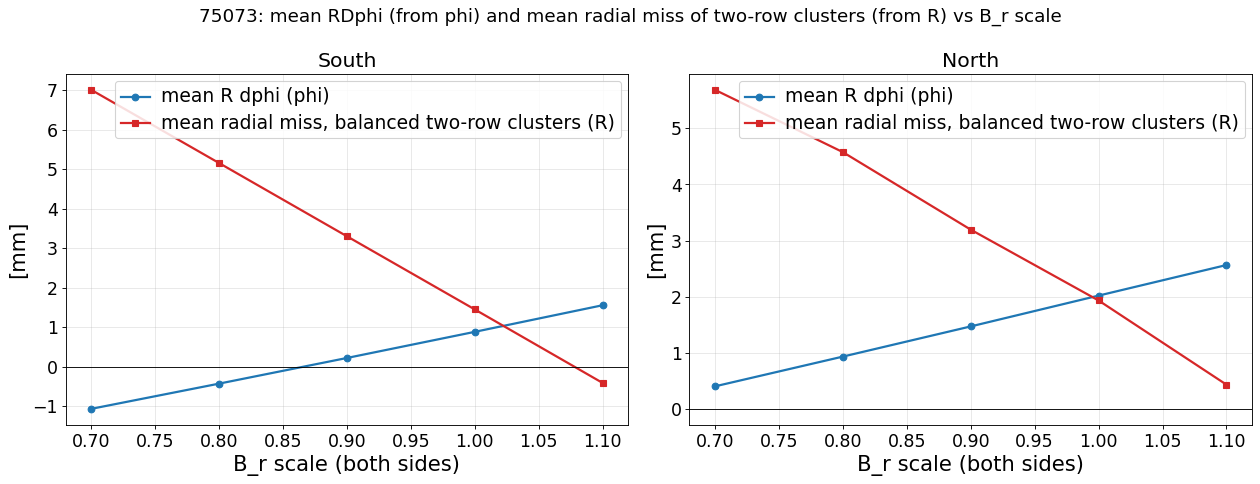

In [10]:
print('CONFIG  75073, step-2 baseline; bsQ scan (B_phi / B_r); truth aligned from RDphi only')
show(ta.fig_step3_rdphi(), ta.fig_step3_br())

**Result.**
- **B_φ** flattens RΔφ (rms 0.9 / 2.0 → 0.19 / 0.24 mm), but only with B_φ/B_z = −0.99 mrad in South and +2.25 mrad in
  North: opposite B_φ in the two halves (a common B_φ adds to one side and subtracts on the other). No realistic source
  (field-line twist, axial current) does that.
- **B_r:** φ asks for a smaller B_r (0.87 South, 0.63 North), **R asks for a larger one**: the radial miss is
  +1.45 / +1.93 mm at B_r 1, +5 mm at 0.8, ≈ 0 at 1.1. So B_r scaling (B_r 0.8 of the new static model) fixes φ by
  breaking R.
- So neither B_φ nor B_r scaling: keep **B_r 1, no B_φ**. A RΔφ offset of the same sign in both halves together with a
  radial miss is what a radial electric field does (E_r × B_z does not depend on the drift direction) → step 4
  (IFC / OFC, z).

## 8. Step 4: IFC, OFC and CM z (no beam 75073, aligned baseline) and zero field from R
Baseline: tilt 0.43 / 1.01 mrad, field map (+3.0, −1.6) mm, B_r 1, no B_φ, frames 0. Grid (bsS): IFC
{+60 … −180} × OFC {−120 … +240} V at z 0, and CM z ±20, ±40 (geometry units of the pos string). RΔφ and the σ-free
two-row radial miss per R bin, sector edges excluded.

**What is plotted.**
- The responses per +100 V of IFC and OFC and per +40 in z.
- Baseline and the joint fit (per side IFC, OFC; z common; errors 0.1 mm RΔφ, 0.4 mm R).
- Zero field 78242 (bsZ grid): the two-row radial miss and the best IFC / OFC from R alone (at B = 0 the field cage acts
  fully radially).

CONFIG  75073 bsS (aligned baseline); 78242 bsZ (IFC vs automatic x OFC, frames 0, z 0) with the per-row charge of bsR


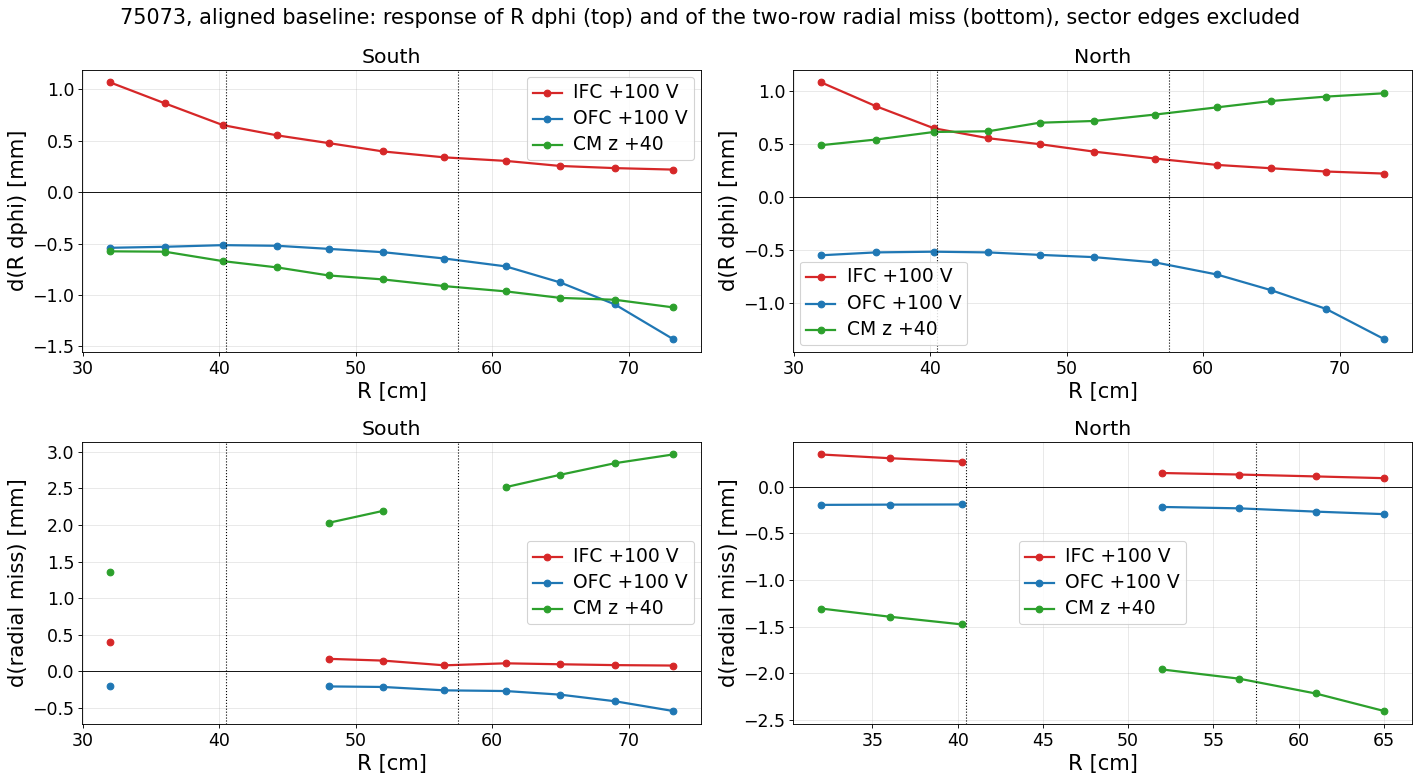

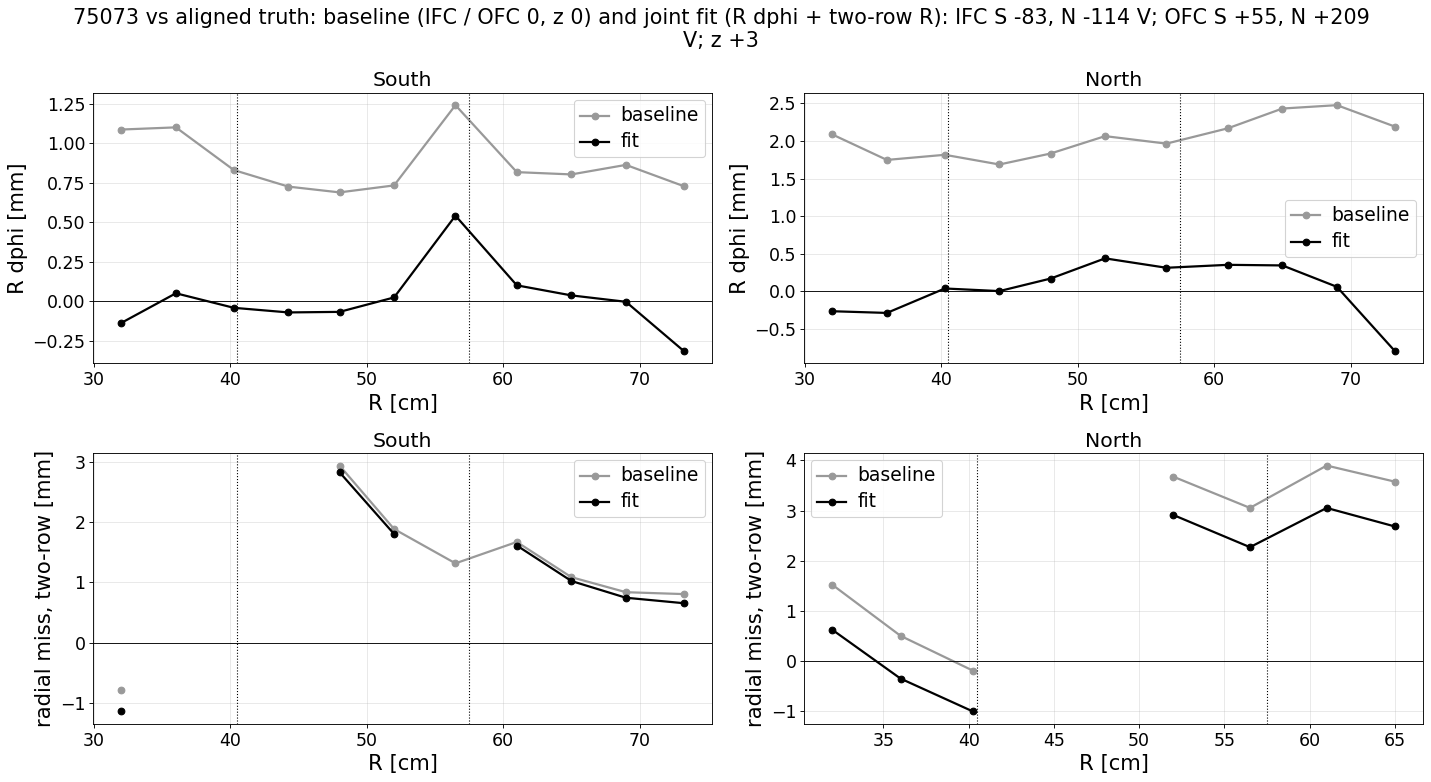

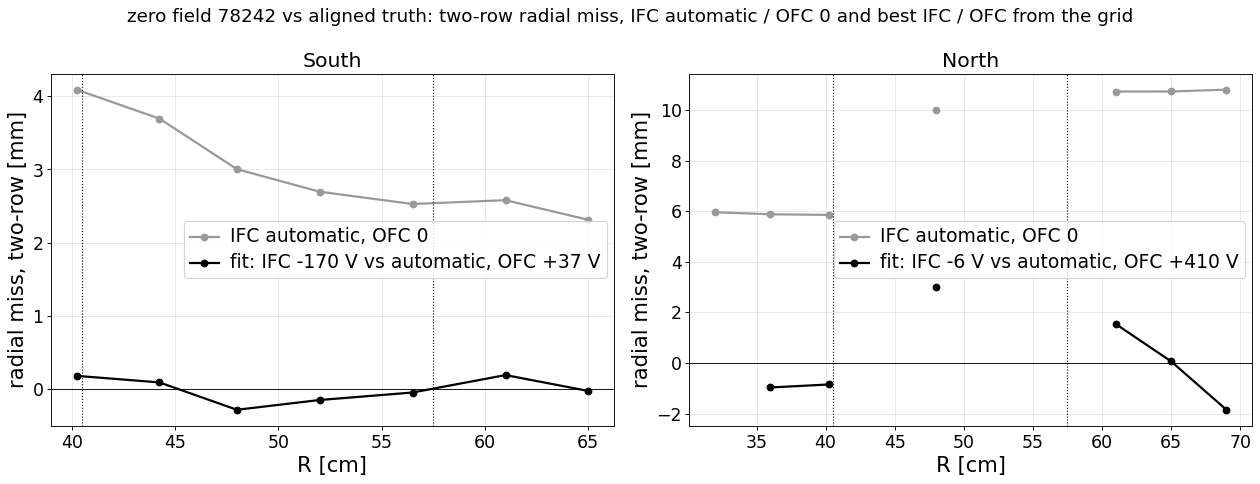

joint fit: I_S -83 +- 31, O_S +55 +- 26, I_N -114 +- 31, O_N +209 +- 27, z +3 +- 7 ; chi2/ndf 484/31
phi  only: I_S -95 +- 26, O_S +95 +- 45, I_N -108 +- 26, O_N +166 +- 42, z -15 +- 17
r    only: I_S +239 +- 277, O_S -862 +- 494, I_N +960 +- 310, O_N +3268 +- 691, z -71 +- 28
zero field South: IFC -170 V vs automatic, OFC +37 V
zero field North: IFC -6 V vs automatic, OFC +410 V


In [11]:
print('CONFIG  75073 bsS (aligned baseline); 78242 bsZ (IFC vs automatic x OFC, frames 0, z 0) with the per-row charge of bsR')
show(ta.fig_step4_resp(), ta.fig_step4_fit(), ta.fig_zf_rfit())
F = ta.s4_fit()
print('joint fit:', ', '.join(f"{k} {v:+.0f} +- {F['err'][k]:.0f}" for k, v in F['val'].items()), f"; chi2/ndf {F['chi2']:.0f}/{F['ndf']}")
for use in (('phi',), ('r',)):
    G = ta.s4_fit(use=use)
    print(f"{'+'.join(use):4s} only:", ', '.join(f"{k} {v:+.0f} +- {G['err'][k]:.0f}" for k, v in G['val'].items()))
for s in (0, 1):
    Z = ta.zf_rfit(s)
    print(f"zero field {c.SIDES[s]}: IFC {Z['best'][0]:+.0f} V vs automatic, OFC {Z['best'][1]:+.0f} V")

**Result.**
- **Responses** (linear, ± symmetric): IFC +100 V → RΔφ +1.1 mm at 32 cm falling ∝ 1/r to +0.2 mm, R +0.4 → +0.1 mm;
  OFC +100 V → RΔφ −0.5 → −1.4 mm (outer), R −0.2 → −0.55 mm; CM z +40 → RΔφ −0.5…−1.1 (South), mirrored in North, and
  R +1.3…+2.8 mm (South), mirrored. With B on, R moves ~3× less than RΔφ for the field cage (ωτ), but more for z.
- **B on, joint fit:** IFC S −83 ± 31, N −114 ± 31 V; OFC S +55 ± 26, N +209 ± 27 V; z +3 ± 7. RΔφ flattens (South
  ±0.15 mm, North ±0.4 mm), but the two-row radial miss stays +1…+3 mm: no field-cage / z combination removes it
  (R alone gives unphysical voltages). The IFC agrees with the φ-only new static model (S −60, N −120).
- **Zero field, from R:** South IFC −170 V vs automatic (= +41 V absolute), OFC +37 V, R flat to ±0.3 mm. The OFC agrees
  with B on (+55 V); the IFC is not comparable (78242 is after the South IFC incident, 75073 before).
  North needs +6…+11 mm and no IFC / OFC fits (best OFC +410 V, residual −2…+3 mm). +11 mm is half the R3 stripe
  spacing: the North zero-field stripe association may be ambiguous; not understood yet.

## 9. Side: PHGarfield frames vs the sector-edge swing
Frame charge scale {0, −90, −180 (default), −360} on both sides (bsF2), zero field 78242 and no beam 75073 on the
aligned baseline. RΔφ vs φ mod 30° of two-row clusters; the sector edge at 15°.

CONFIG  bsF2: 78242 z 0, tilt 0.16/0.85, IFC automatic, OFC 0; 75073 aligned baseline (IFC / OFC 0); frame scale scanned


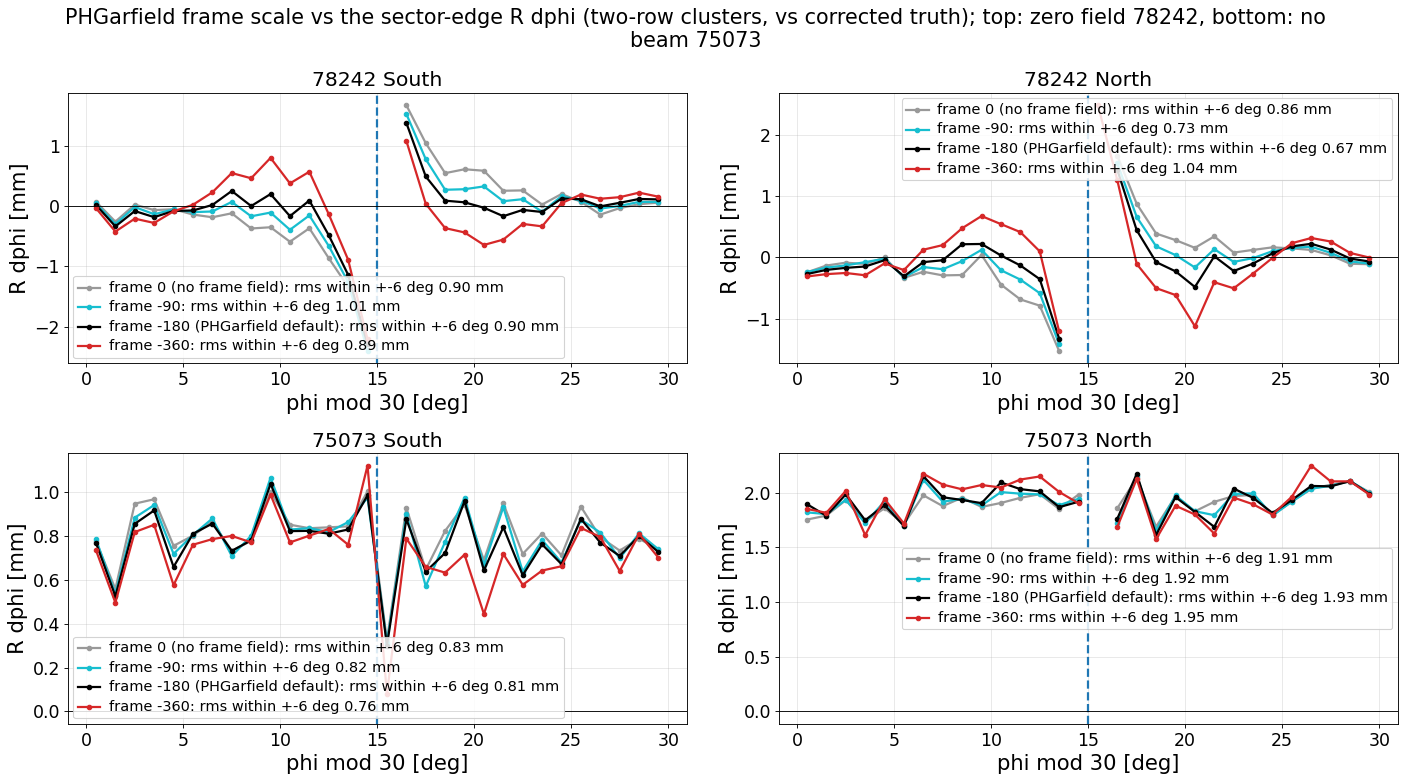

In [12]:
print('CONFIG  bsF2: 78242 z 0, tilt 0.16/0.85, IFC automatic, OFC 0; 75073 aligned baseline (IFC / OFC 0); frame scale scanned')
show(ta.fig_frames())

**Result.**
- **Zero field:** frame −180 … −270 removes the tail 4–10° from the edge (±0.5 → ±0.1 mm); more over-corrects it. The
  steep part within ~2° of the gap (−1…−2.3 / +1.4 mm) stays at any scale: the frames get the reach, not the near-gap
  shape.
- **No beam (B on):** no edge swing in RΔφ at all, for any frame scale (with B on, electrons follow the field lines; a
  field at the gap moves them radially, not in φ). So for B-on RΔφ the frames do not matter; sector edges are still
  excluded everywhere.

## 10. Beam: keff on the aligned static model, then closure
Static model of sections 2–8 (tilt 0.43 / 1.01, field map (+3.0, −1.6) mm, z 0, B_r 1, no B_φ, frames 0, IFC S −83 /
N −114 V, OFC S +55 / N +209 V; South +211 V automatic after 75800). 17 beam blocks, R1 current 1.8–7.0: maps {BEST
(α 1.6), prod 1.6, α 1.8, prod 2.0} × b {0.45 … 0.90}, keff = b × I_R1 per side; the same without the field-cage offsets;
on 4 blocks the field cage ±60 V (IFC) × ±100 V (OFC) × b. RΔφ vs the corrected truth, sector edges excluded.

### 10a. Determining keff
**What is plotted.** Best b per block vs I_R1 for every map (filled: vs truth, open: beam − no beam); red squares:
without the field-cage offsets. Below: nested fits (4 field-cage blocks + no beam, RΔφ only).

CONFIG  v4 beam scan (bsK, bsKJ); BEST = a1p6_r22p75_w2_o0


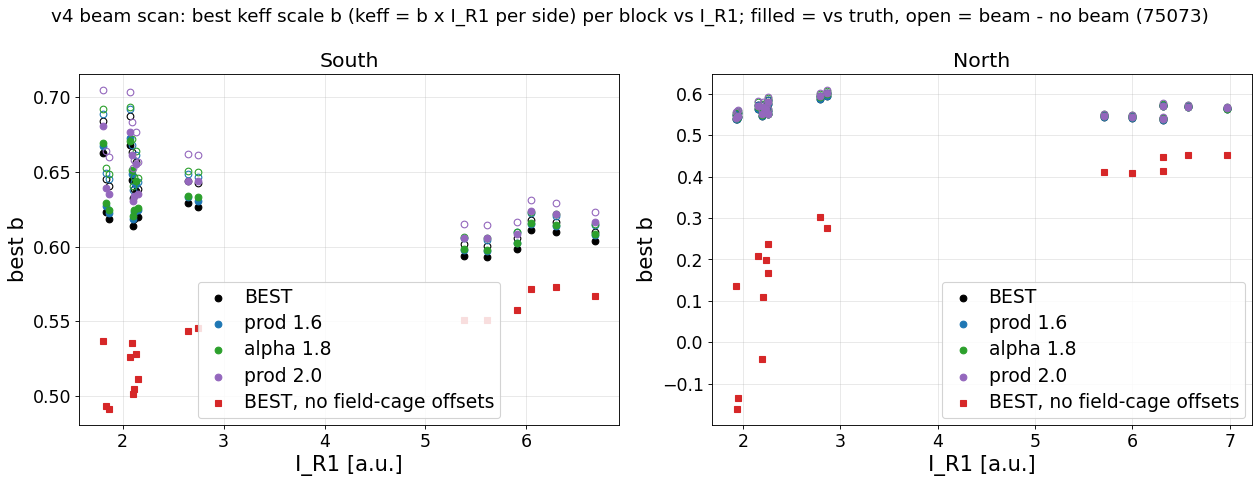

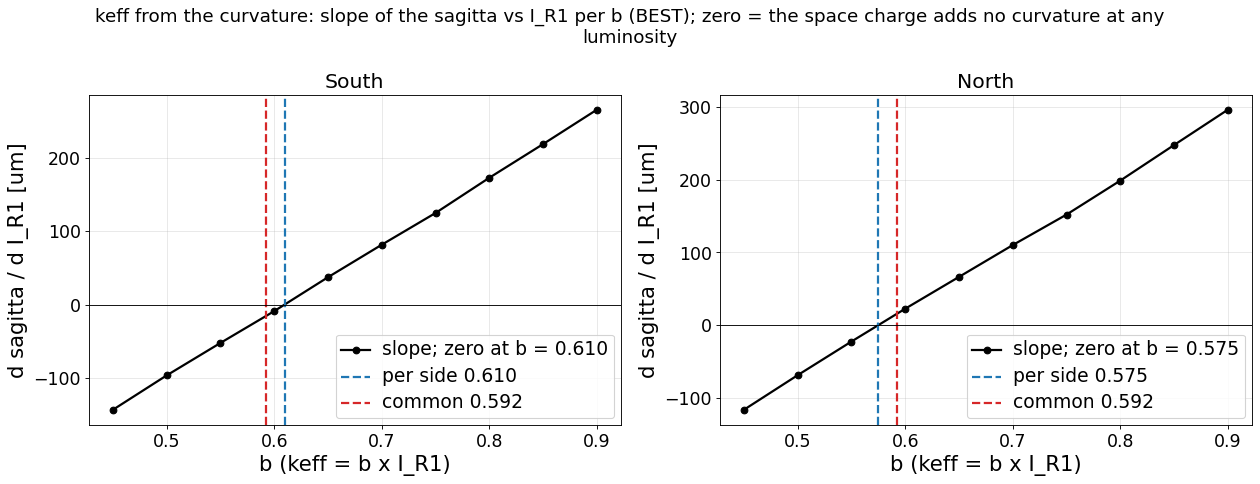

BEST       South: best b 0.622 +- 0.021 (vs truth), 0.637 (beam - no beam); R dphi rms at best 0.28 mm (high lumi 0.29)
BEST       North: best b 0.558 +- 0.017 (vs truth), 0.566 (beam - no beam); R dphi rms at best 0.38 mm (high lumi 0.33)
prod 1.6   South: best b 0.626 +- 0.021 (vs truth), 0.641 (beam - no beam); R dphi rms at best 0.28 mm (high lumi 0.30)
prod 1.6   North: best b 0.558 +- 0.017 (vs truth), 0.566 (beam - no beam); R dphi rms at best 0.38 mm (high lumi 0.33)
alpha 1.8  South: best b 0.627 +- 0.021 (vs truth), 0.644 (beam - no beam); R dphi rms at best 0.30 mm (high lumi 0.38)
alpha 1.8  North: best b 0.561 +- 0.018 (vs truth), 0.569 (beam - no beam); R dphi rms at best 0.47 mm (high lumi 0.53)
prod 2.0   South: best b 0.636 +- 0.022 (vs truth), 0.654 (beam - no beam); R dphi rms at best 0.40 mm (high lumi 0.64)
prod 2.0   North: best b 0.562 +- 0.018 (vs truth), 0.571 (beam - no beam); R dphi rms at best 0.59 mm (high lumi 0.78)
BEST without field-cage offsets South: b

In [13]:
print('CONFIG  v4 beam scan (bsK, bsKJ); BEST = a1p6_r22p75_w2_o0')
show(ta.fig_v4_keff(), ta.fig_sag_slope())
for m, lab in ta.V4_MAPS:
    S_ = ta.v4_summary(m)
    for s in (0, 1):
        x = np.array([r[3:] for r in S_ if r[2] == s])
        print(f"{lab:10s} {c.SIDES[s]:5s}: best b {x[:, 1].mean():.3f} +- {x[:, 1].std():.3f} (vs truth), {x[:, 2].mean():.3f} (beam - no beam); "
              f"R dphi rms at best {x[:, 3].mean():.2f} mm (high lumi {x[x[:, 0] > 4, 3].mean():.2f})")
S_ = ta.v4_summary(ta.V4_MAPS[0][0], 'v4nofc')
for s in (0, 1):
    x = np.array([r[3:] for r in S_ if r[2] == s])
    print(f"BEST without field-cage offsets {c.SIDES[s]}: best b {x[:, 1].mean():.3f} +- {x[:, 1].std():.3f}, R dphi rms {x[:, 3].mean():.2f} mm")
print()
D_ = ta.minimal_data()
for m in ([], ['b'], ['bS', 'bN'], ['b', 'c'], ['b', 'oS', 'oN'], ['b', 'iS', 'iN', 'oS', 'oN'], ['bS', 'bN', 'iS', 'iN', 'oS', 'oN']):
    F = ta.minimal_fit(D_, m, use_r=False)
    par = ' '.join(f"{k} {v + 0.6 if k.startswith('b') else v:+.3g}" for k, v in F['par'].items())
    print(f"{'+'.join(m) or 'fit point, b 0.60':22s} R dphi rms S {F['phi_rms_0']:.2f} N {F['phi_rms_1']:.2f} mm | {par}")

**Result.**
- keff ∝ GEM current: the best b is the same in all 17 blocks (BEST: South 0.62 ± 0.02, North 0.56 ± 0.02; beam − no
  beam the same within 0.01). A constant keff offset does not help.
- The field-cage offsets are needed (without them North b 0.23 ± 0.19, RΔφ rms 1.8 mm); freed in the beam fit they
  move < 30 V.
- BEST ≈ prod 1.6; α 1.8 and prod 2.0 get worse at high luminosity → α 1.6.
- **Curvature criterion** (reference-free: the slope of the sagitta vs I_R1 must vanish, the space charge must not add
  curvature at any luminosity): **b = 0.610 South, 0.575 North** (6 % apart; the RΔφ rms prefers 0.62 / 0.56, 11 %).
  The static sagitta left at I = 0 is +10…+20 µm South, +40…+50 µm North.
- **One keff per GEM current for both sides: b = 0.592** leaves ±16 µm per unit I_R1 (≈ ±80 µm between the lowest and
  the highest luminosity) and costs ≈ 0.03 mm of RΔφ rms. Final model below; the per-side values are shown with it.

### 10b. Closure at the final model: beam vs truth, vs no beam, vs field off
Final model: aligned static + α 1.6 (BEST) with **keff = 0.592 × I_R1 on both sides** (blue: per side 0.610 / 0.575);
production = CDB static + CDB 3D maps at the CDB keff. Each beam block against four references, each corrected with its own model:
the CM truth; no beam 75073 and 83319 (no space charge, same static model); field off 78242 (no B, no space charge).
A track absorbs a constant, a rotation and a curvature of RΔφ(R): the **sagitta** (vertex-constrained slope of
dφ = RΔφ / R vs R, 5290 µm per mrad/cm) is what biases the momentum; the rotation does not.

**What is plotted.**
- RΔφ vs R per block for the final model (colour = I_R1), production as the mean of the blocks.
- Sagitta and RΔφ rms per block vs I_R1, production vs final.

CONFIG  final: aligned static + BEST at keff = 0.592 x I_R1 (both sides, interpolated between b 0.55 and 0.60); production: CDB


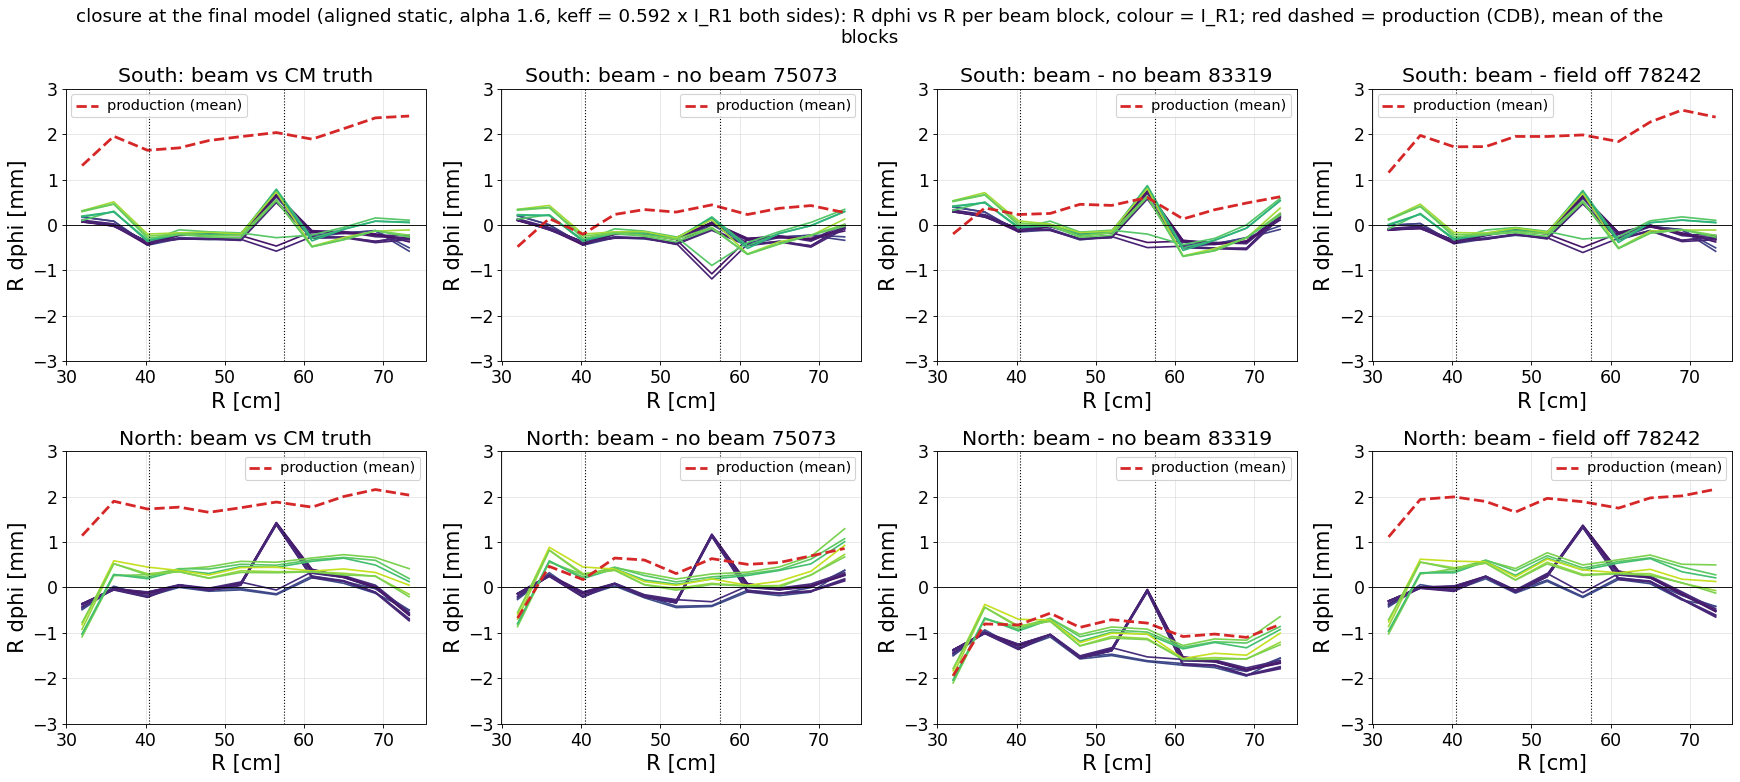

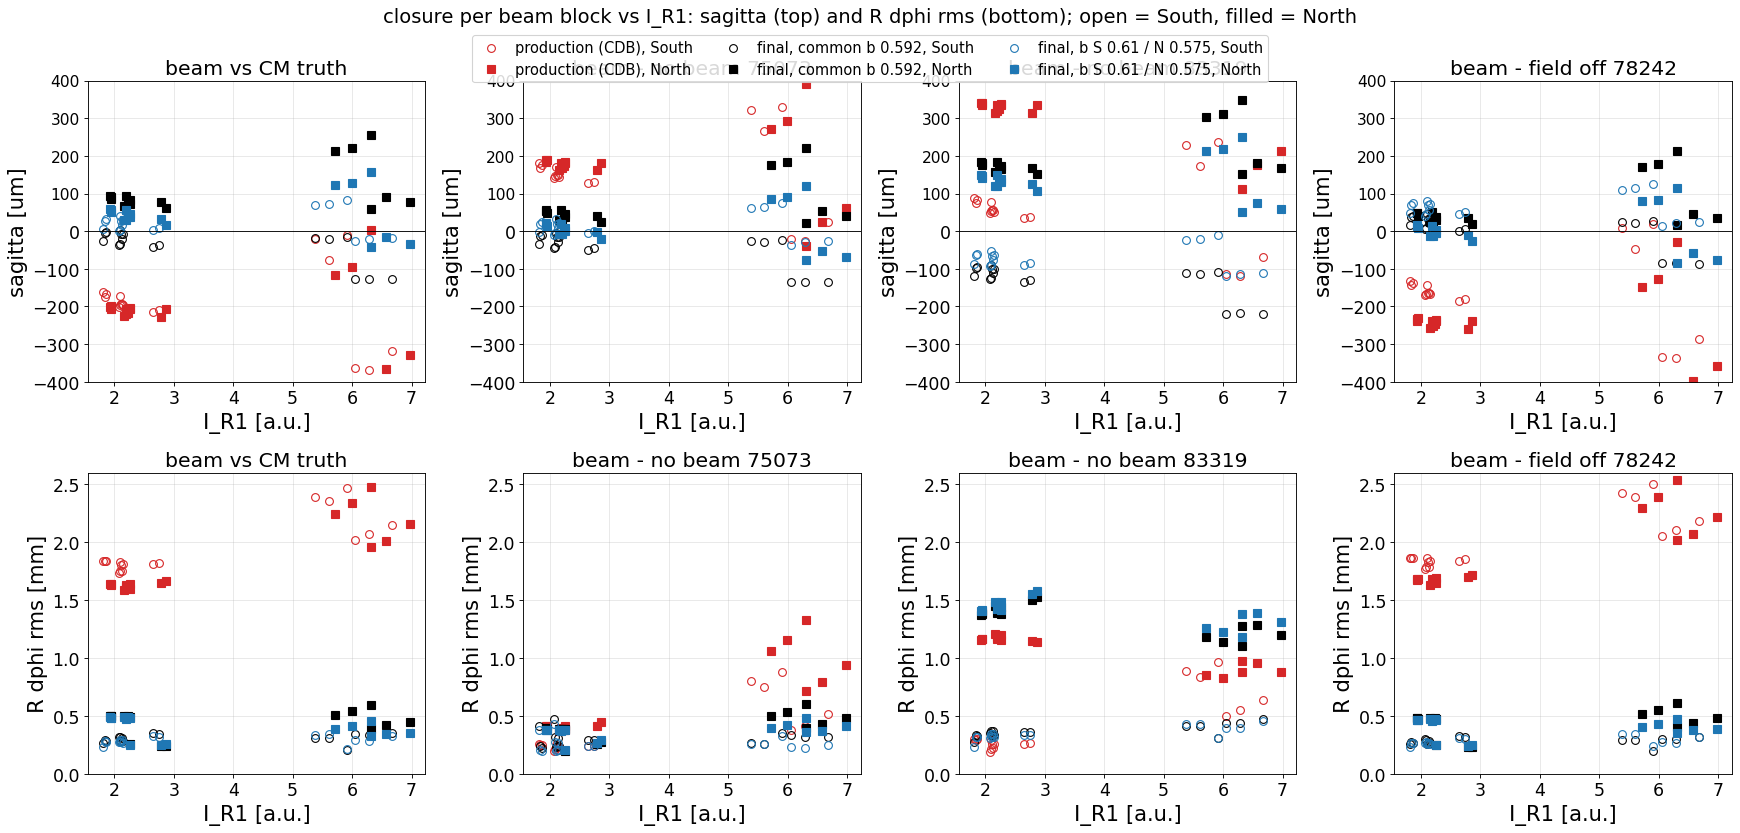

S beam vs CM truth         production (CDB)                           sagitta  -190 +-  95 um | R dphi rms 1.96 mm | DCA +1.2 mm
S beam vs CM truth         final, common b 0.592                      sagitta   -38 +-  43 um | R dphi rms 0.31 mm | DCA +0.6 mm
S beam vs CM truth         final, b S 0.61 / N 0.575                  sagitta   +21 +-  31 um | R dphi rms 0.29 mm | DCA -0.1 mm
S beam - no beam 75073     production (CDB)                           sagitta  +152 +-  95 um | R dphi rms 0.37 mm | DCA -2.8 mm
S beam - no beam 75073     final, common b 0.592                      sagitta   -46 +-  43 um | R dphi rms 0.30 mm | DCA +2.4 mm
S beam - no beam 75073     final, b S 0.61 / N 0.575                  sagitta   +13 +-  31 um | R dphi rms 0.26 mm | DCA +1.7 mm
S beam - no beam 83319     production (CDB)                           sagitta   +59 +-  95 um | R dphi rms 0.42 mm | DCA -1.2 mm
S beam - no beam 83319     final, common b 0.592                      sagitta  -130 +-  43 um | R

In [14]:
print(f'CONFIG  final: aligned static + BEST at keff = {ta.B_FINAL} x I_R1 (both sides, interpolated between b 0.55 and 0.60); production: CDB')
show(ta.fig_closure_profiles(), ta.fig_closure_crit())
for s in (0, 1):
    for ref, rl in ta.REFS3:
        for st, lab, _ in ta.STAGES:
            C = ta.closure(st, ref, s); sg = np.array([q[3] for q in C]); d = np.array([q[2] for q in C])
            rms = np.array([np.sqrt(np.nanmean(q[1] ** 2)) for q in C])
            print(f"{c.SIDES[s][0]} {rl:24s} {lab:42s} sagitta {np.nanmean(sg):+5.0f} +- {np.nanstd(sg):3.0f} um | R dphi rms {np.nanmean(rms):.2f} mm | DCA {np.nanmean(d):+.1f} mm")

**Result.**
- **RΔφ:** the final model closes to 0.3–0.4 mm rms against the truth, no beam 75073 and field off, at every
  luminosity. Production is at 1.8–2.0 mm against the truth and field off; it looks good only in beam − no beam
  (0.4 / 0.6 mm), where its static error cancels.
- **Sagitta** (mean over the 17 blocks; vs truth / beam − no beam 75073 / beam − field off):

  | | South [µm] | North [µm] |
  |---|---|---|
  | production (CDB) | −190 / +152 / −161 | −215 / +174 / −246 |
  | final, common b 0.592 | −38 / −46 / +4 | +105 / +68 / +62 |
  | final, b 0.610 / 0.575 | +21 / +13 / +62 | +45 / +9 / +2 |

  Production grows with luminosity (to −350 µm at I_R1 ≈ 6.5). The final model with the per-side keff is flat in
  luminosity at the static value; with the common keff it drifts by ±16 µm per unit I_R1 (mostly visible in North:
  +50 → +150 µm). At the same current the high-luminosity runs scatter by ~±100 µm between blocks.
- **No beam 83319** as the reference is worse for both models (South sagitta −100 µm lower; North RΔφ rms 1.4 mm):
  83319 itself differs from 75073 (North rigidly rotated by 2.4 mrad), so the two no-beam runs disagree by more than the
  closure of the beam runs. 75073 stays the reference.
- The DCA (quadratic extrapolation to R = 0) is dominated by the outermost bins and is not robust (e.g. North vs truth
  −4 mm from one −0.9 mm bin at 73 cm); it is shown in the table only.
- Not closed: the static sagitta (+10…+50 µm at I = 0), the 6 % South / North keff difference, and the two-row radial
  miss (South +2.4, North −1.8 mm with beam), which does not depend on the space charge.